In [41]:
# Cellule 1 : Importation des bibliothèques nécessaires
# Cette cellule permet de charger l'ensemble des modules requis :
# PyTorch pour le Deep Learning, NumPy pour la manipulation de tableaux de données,
# tqdm pour afficher les barres de progression et torchvision pour le traitement des images.
import torch
import torch.nn as nn
import numpy as np
from tqdm import tqdm
from torchvision.utils import save_image, make_grid

In [42]:
# Cellule 2 : Définition des hyperparamètres globaux
# Cette cellule configure l'environnement d'apprentissage : chemin de stockage des images, taille des lots,
# nombre d'échantillons pour la méthode de Monte Carlo (reparamétrisation), dimension du réseau (image,
# couche cachée et espace latent de dimension 200), taux d'apprentissage (lr) et nombre d'époques.
dataset_path = '~/datasets'  # Répertoire de stockage pour le dataset
batch_size = 100            # Taille des lots (mini-batch) pour l'entraînement
L = 10                      # Nombre d'échantillons de Monte Carlo pour la reparamétrisation

# Dimensions du réseau
x_dim  = 784                # Dimension d'entrée (28x28 pixels aplatis pour MNIST)
hidden_dim = 400            # Dimension de la couche cachée de l'encodeur/décodeur
latent_dim = 200            # Dimension de l'espace latent

lr = 1e-3                   # Taux d'apprentissage pour l'optimiseur
epochs = 5                  # Nombre d'époques pour l'entraînement

In [43]:
# Cellule 3 : Téléchargement et préparation des données MNIST
# Cette cellule charge les images de chiffres manuscrits (MNIST), les convertit en tenseurs
# exploitables par PyTorch et crée des générateurs de données (DataLoaders) pour charger
# automatiquement les images par paquets de 100 durant l'entraînement.
from torchvision.datasets import MNIST
import torchvision.transforms as transforms
from torch.utils.data import DataLoader

# Transformation de l'image en tenseur PyTorch
mnist_transform = transforms.Compose([
        transforms.ToTensor(),
])

# Initialisation des jeux d'entraînement et de test
train_dataset = MNIST(dataset_path, transform=mnist_transform, train=True, download=True)
test_dataset  = MNIST(dataset_path, transform=mnist_transform, train=False, download=True)
test_labels = test_dataset.targets

# Création des DataLoaders pour l'itération automatique par mini-lots
train_loader = DataLoader(dataset=train_dataset, batch_size=batch_size, shuffle=True)
test_loader  = DataLoader(dataset=test_dataset,  batch_size=batch_size, shuffle=False)

In [44]:
# Cellule 4 : Définition du réseau de l'Encodeur
# L'encodeur sert à projeter l'image de départ (784 dimensions) vers un espace intermédiaire.
# Il estime ensuite et renvoie deux paramètres statistiques essentiels de la distribution latente :
# la moyenne (mean) et le logarithme de la variance (log_var).
class Encoder(nn.Module):
    def __init__(self, input_dim, hidden_dim, latent_dim):
        super(Encoder, self).__init__()
        # Couches denses pour projeter l'image d'entrée
        self.FC_enc1 = nn.Linear(input_dim, hidden_dim)
        self.FC_enc2 = nn.Linear(hidden_dim, hidden_dim)
        # Couches de sortie pour estimer la moyenne (mean) et la log-variance du profil latent
        self.FC_mean = nn.Linear(hidden_dim, latent_dim)
        self.FC_var  = nn.Linear (hidden_dim, latent_dim)

        self.LeakyReLU = nn.LeakyReLU(0.2)  # Fonction d'activation non-linéaire
        self.training = True

    def forward(self, x):
        h_1     = self.LeakyReLU(self.FC_enc1(x))
        h_2     = self.LeakyReLU(self.FC_enc2(h_1))
        mean    = self.FC_mean(h_2)
        log_var = self.FC_var(h_2)
        return mean, log_var

In [45]:
# Cellule 5 : Définition du réseau du Décodeur
# Le décodeur effectue le travail inverse de l'encodeur : il prend un point échantillonné
# de l'espace latent (de dimension 200) et tente de reconstruire l'image d'origine sous forme
# de probabilités de pixels (grâce à l'activation finale Sigmoid).
class Decoder(nn.Module):
    def __init__(self, latent_dim, hidden_dim, output_dim):
        super(Decoder, self).__init__()
        # Couches de projection depuis l'espace latent vers la dimension d'origine
        self.FC_dec1   = nn.Linear(latent_dim, hidden_dim)
        self.FC_dec2   = nn.Linear(hidden_dim, hidden_dim)
        self.FC_output = nn.Linear(hidden_dim, output_dim)

        self.LeakyReLU = nn.LeakyReLU(0.2)

    def forward(self, z):
        h_out_1  = self.LeakyReLU(self.FC_dec1(z))
        h_out_2  = self.LeakyReLU(self.FC_dec2(h_out_1))
        # Activation Sigmoïde pour contraindre les pixels de sortie entre 0 et 1
        theta = torch.sigmoid(self.FC_output(h_out_2))
        return theta

In [46]:
# Cellule 6 : Modèle global (Auto-encodeur avec astuce de reparamétrisation)
# Cette classe orchestre l'encodeur et le décodeur. Elle implémente l'astuce de reparamétrisation
# (reparameterization trick) indispensable pour permettre la rétropropagation du gradient
# malgré la nature stochastique (échantillonnage Gaussien) de l'espace latent.
class Model(nn.Module):
    def __init__(self, Encoder, Decoder):
        super(Model, self).__init__()
        self.Encoder = Encoder
        self.Decoder = Decoder

    def reparameterization(self, mean, var):
        # Astuce de reparamétrisation pour propager les gradients à travers l'échantillonnage de Monte Carlo
        eps = torch.randn((L, batch_size, latent_dim))
        mean = mean.unsqueeze(0)
        var = var.unsqueeze(0)
        z = mean + var * eps
        return z

    def forward(self, x):
        mean, log_var = self.Encoder(x)
        z = self.reparameterization(mean, torch.exp(log_var))
        theta = self.Decoder(z)
        return theta, mean, log_var, z

In [47]:
# Cellule 7 : Instanciation du premier modèle (VAE Classique)
# Ici, on crée de manière concrète notre premier modèle Auto-encodeur Variationnel (VAE) en
# lui fournissant un objet Encoder et un objet Decoder fraîchement configurés avec nos dimensions.
encoder = Encoder(input_dim=x_dim, hidden_dim=hidden_dim, latent_dim=latent_dim)
decoder = Decoder(latent_dim=latent_dim, hidden_dim = hidden_dim, output_dim = x_dim)
model = Model(Encoder=encoder, Decoder=decoder)

In [48]:
# Cellule 8 : Perte standard du VAE et Optimiseur
# Cette fonction implémente la formule de l'ELBO (Evidence Lower Bound) à minimiser.
# Elle comprend : 1) La vraisemblance de reconstruction (Bernoulli) pour s'assurer de la ressemblance visuelle.
# 2) La divergence KL (Kullback-Leibler) qui force la distribution latente à ressembler à une loi normale standard.
from torch.optim import Adam

def loss_function(x, theta, mean, log_var):
    # Calcul du terme de reconstruction (Log-vraisemblance de Bernoulli)
    x = x.unsqueeze(0)
    x = x.expand(theta.size(0), -1, -1)
    likelihood_per_sample = torch.sum(x * torch.log(theta + 1e-7) + (1 - x) * torch.log(1 - theta + 1e-7), dim=-1)
    likelihood_MC = torch.mean(likelihood_per_sample, dim=0)
    likelihood = torch.mean(likelihood_MC)

    # Calcul du terme de régularisation (Divergence KL avec une Gaussienne standard)
    var = torch.exp(log_var)
    kl = 0.5 * torch.mean(torch.sum(var + mean**2 - 1 - log_var, dim=-1))

    # La perte globale à minimiser est KL - reconstruction (vraisemblance)
    loss = kl - likelihood
    return loss

optimizer = Adam(model.parameters(), lr=lr)

In [9]:
print("Start training VAE...")
model.train()

for epoch in range(epochs):
    overall_loss = 0
    for batch_idx, (x, _) in enumerate(train_loader):
        x = x.view(batch_size, x_dim)
        x = torch.round(x)

        optimizer.zero_grad()

        theta, mean, log_var, z = model(x)
        loss = loss_function(x, theta, mean, log_var)

        overall_loss += loss.item()

        loss.backward()
        optimizer.step()

    print("\tEpoch", epoch + 1, "complete!", "\tAverage Loss: ", overall_loss / (batch_idx*batch_size))

print("Finish!!")

Start training VAE...
	Epoch 1 complete! 	Average Loss:  1.554356010195011
	Epoch 2 complete! 	Average Loss:  0.9667906935346345
	Epoch 3 complete! 	Average Loss:  0.8285077187055737
	Epoch 4 complete! 	Average Loss:  0.7707524443866812
	Epoch 5 complete! 	Average Loss:  0.7326372813382411
Finish!!


In [10]:
model.eval()
# below we get decoder outputs for test data
with torch.no_grad():
    z_test = []
    x_test = []
    for batch_idx, (x, _) in enumerate(tqdm(test_loader)):
        x = x.view(batch_size, x_dim)
        x_test.append(x)
        z = model.forward(x)[-1]
        z_test.append(z)
        theta = model.forward(x)[0][0]

100%|██████████| 100/100 [00:05<00:00, 17.89it/s]


In [11]:
import matplotlib.pyplot as plt
def show_image(theta, idx):
    x_hat = theta.view(batch_size, 28, 28)
    #x_hat = Bernoulli(x_hat).sample() # sample pixel values (you can also try this, and observe how the generated images look)
    fig = plt.figure()
    plt.imshow(x_hat[idx].cpu().numpy(), cmap='gray')

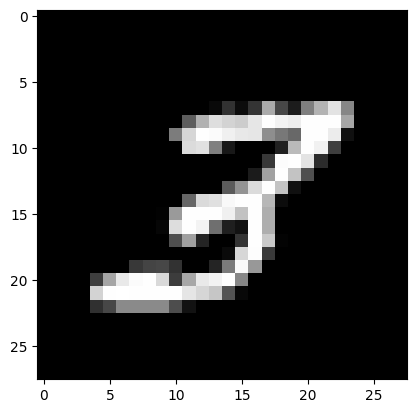

In [12]:
show_image(x, idx=25) # try different indices as well

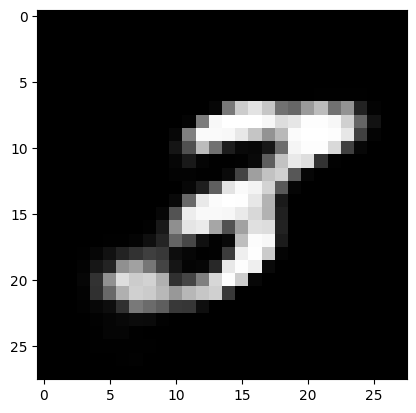

In [13]:
show_image(theta, idx=25)

In [14]:
with torch.no_grad():
    noise = torch.randn(batch_size, latent_dim)
    generated_images = decoder.forward(noise)

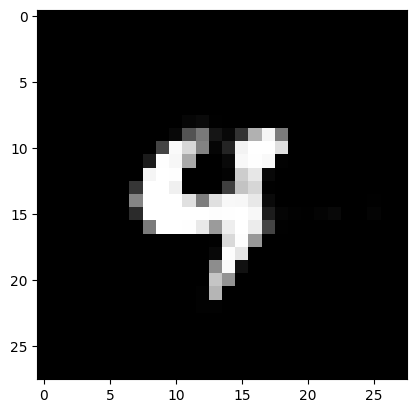

In [15]:
show_image(generated_images, idx=25)

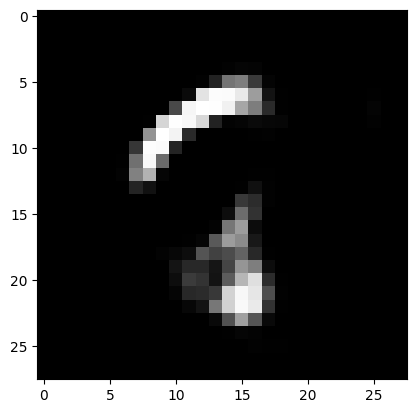

In [16]:
show_image(generated_images, idx=1)

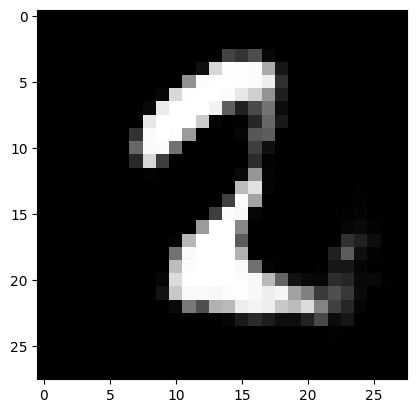

In [17]:
show_image(generated_images, idx=27)

In [18]:
from sklearn.manifold import TSNE
def get_2d_representations(z):
    tsne = TSNE()
    rep_2D = tsne.fit_transform(z)
    return rep_2D

In [19]:
z_test_array = np.array(z_test)[:,0,:,:].reshape(10000,200)
x_test_array = np.array(x_test).reshape(10000,784)
# Project the latent representations of first 200 test data into 2D
rep_2d = get_2d_representations(z_test_array[:200,:])

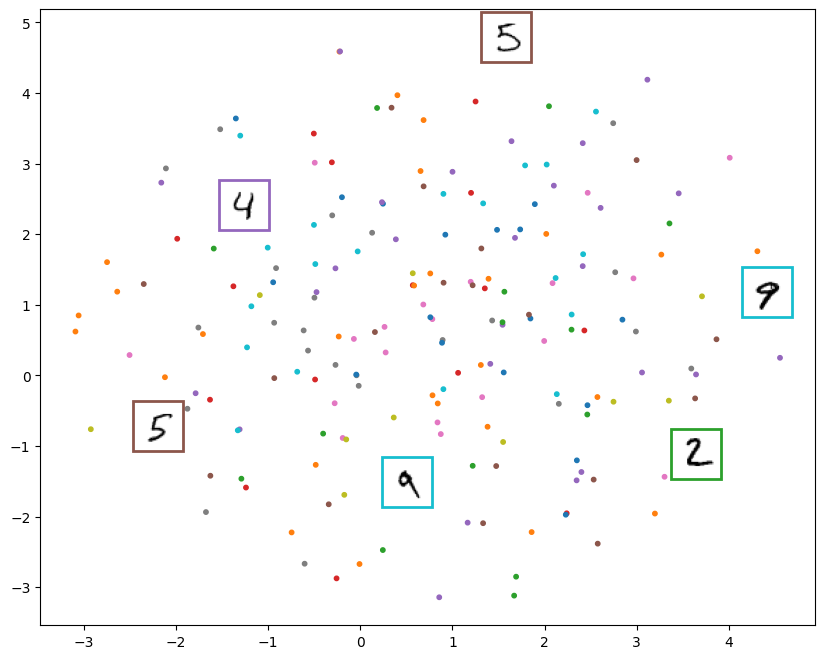

In [20]:
from matplotlib.offsetbox import (AnnotationBbox, DrawingArea, OffsetImage,
                                  TextArea)
fig = plt.figure(figsize=(10, 8))
cmap = plt.cm.tab10
plt.scatter(rep_2d[:, 0], rep_2d[:, 1], c=test_labels[:200], s=10, cmap=cmap)
image_positions = np.array([[1.0, 1.0]])
dist_coord1 = np.max(rep_2d[:, 0]) - np.min(rep_2d[:, 0])
dist_coord2 = np.max(rep_2d[:, 1]) - np.min(rep_2d[:, 1])
target_dist = np.sqrt(dist_coord1**2+dist_coord2**2)/2
for index, position in enumerate(rep_2d):
      dist = np.sum((position - image_positions) ** 2, axis=1)
      if np.min(dist) > target_dist:  # if far enough from other images
          image_positions = np.r_[image_positions, [position]]
          imagebox = AnnotationBbox(
              OffsetImage(x_test_array[index].reshape(28, 28), cmap="binary"),
              position,
              bboxprops={"edgecolor": tuple(cmap([test_labels[:200][index]])[0]), "lw": 2},
          )
          plt.gca().add_artist(imagebox)

In [49]:
# Cellule 9 : Noyau Gaussien (RBF Kernel)
# Cette fonction mathématique calcule le noyau de fonction à base radiale (RBF) entre deux ensembles
# de points latents. Il est nécessaire pour évaluer la distance de distribution non-paramétrique dans l'approche WAE.
def compute_rbf(x1: torch.Tensor, x2: torch.Tensor, latent_var: float = 2.0, eps: float = 1e-7) -> torch.Tensor:
    z_dim = x2.size(-1)
    sigma = (2.0 / z_dim) * latent_var
    result = torch.exp(-((x1 - x2).pow(2).mean(-1) / sigma))
    return result

In [50]:
# Cellule 10 : Évaluation de l'écart MMD (Maximum Mean Discrepancy)
# Calcule l'écart statistique MMD à l'aide des noyaux RBF calculés sur les données latentes réelles
# et les échantillons du bruit a priori (prior). Le but est de s'assurer que l'ensemble du codage s'aligne bien sur le prior.
def MMD(prior_z: torch.Tensor, z: torch.Tensor):
    k_pp = compute_rbf(prior_z, prior_z)
    k_pq = compute_rbf(prior_z, z)
    k_qq = compute_rbf(z, z)
    # Équation empirique du calcul de la MMD
    mmd = k_pp - 2 * k_pq + k_qq
    return mmd

In [51]:
# Cellule 11 : Définition de la perte WAE-MMD
# Au lieu de la divergence KL classique d'un VAE, cette fonction calcule la perte du Wasserstein Autoencoder.
# Elle couple la reconstruction d'image classique avec la contrainte globale MMD (mesurant l'écart avec le prior Gaussien).
def loss_mmd (x, theta, z):
    # Calcul de la reconstruction
    x = x.unsqueeze(0)
    x = x.expand(theta.size(0), -1, -1)
    likelihood_per_sample = torch.sum(x * torch.log(theta + 1e-7) + (1 - x) * torch.log(1 - theta + 1e-7), dim=-1)
    likelihood_MC = torch.mean(likelihood_per_sample, dim=0)
    likelihood = torch.mean(likelihood_MC)

    # Calcul de l'écart MMD entre les échantillons latents et un prior normal standardisé
    prior_z = torch.randn_like(z)
    mmd_per_sample = MMD(prior_z, z)
    mmd_MC = torch.mean(mmd_per_sample)
    mmd = torch.mean(mmd_MC)

    loss = mmd - likelihood
    return loss

In [52]:
# Cellule 12 : Instanciation du second modèle (WAE-MMD)
# Instanciation de nouveaux composants (Encodeur 2 et Décodeur 2) indépendants du premier VAE pour entraîner
# notre deuxième modèle (WAE-MMD) basé sur la perte par divergence de Wasserstein (MMD).
encoder_2 = Encoder(input_dim=x_dim, hidden_dim=hidden_dim, latent_dim=latent_dim)
decoder_2 = Decoder(latent_dim=latent_dim, hidden_dim = hidden_dim, output_dim = x_dim)
model_2 = Model(Encoder=encoder_2, Decoder=decoder_2)
optimizer_2 = Adam(model_2.parameters(), lr=lr)

In [25]:
print("Start training VAE...")
model_2.train()

for epoch in range(epochs):
    overall_loss = 0
    for batch_idx, (x, _) in enumerate(train_loader):
        x = x.view(batch_size, x_dim)
        x = torch.round(x)

        optimizer_2.zero_grad()

        theta_2, mean_2, log_var_2, z_2 = model_2(x)
        loss_2 = loss_mmd(x, theta_2, z_2)

        overall_loss += loss_2.item()

        loss_2.backward()
        optimizer_2.step()

    print("\tEpoch", epoch + 1, "complete!", "\tAverage Loss: ", overall_loss / (batch_idx*batch_size))

print("Finish!!")

Start training VAE...
	Epoch 1 complete! 	Average Loss:  1.2649896708951769
	Epoch 2 complete! 	Average Loss:  0.6150106965639754
	Epoch 3 complete! 	Average Loss:  0.473167056368667
	Epoch 4 complete! 	Average Loss:  0.40934254991789293
	Epoch 5 complete! 	Average Loss:  0.366407888059027
Finish!!


In [26]:
model_2.eval()
with torch.no_grad():
    z_test = []
    x_test = []
    for batch_idx, (x, _) in enumerate(tqdm(test_loader)):
        x = x.view(batch_size, x_dim)
        x_test.append(x)
        # generate z, which will be displayed later
        z = model_2.forward(x)[-1]
        z_test.append(z)

100%|██████████| 100/100 [00:02<00:00, 36.47it/s]


In [27]:
z_test_array = np.array(z_test)[:,1,:,:].reshape(10000,200)
x_test_array = np.array(x_test).reshape(10000,784)
rep_2d = get_2d_representations(z_test_array[:200,:])

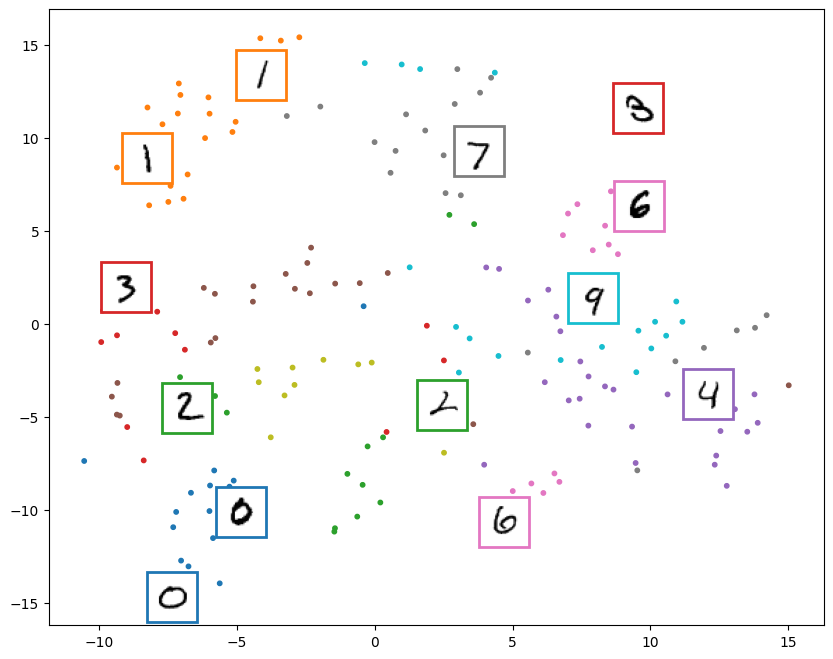

In [28]:
from matplotlib.offsetbox import (AnnotationBbox, DrawingArea, OffsetImage,
                                  TextArea)
fig = plt.figure(figsize=(10, 8))
cmap = plt.cm.tab10
plt.scatter(rep_2d[:, 0], rep_2d[:, 1], c=test_labels[:200], s=10, cmap=cmap)
image_positions = np.array([[1.0, 1.0]])
dist_coord1 = np.max(rep_2d[:, 0]) - np.min(rep_2d[:, 0])
dist_coord2 = np.max(rep_2d[:, 1]) - np.min(rep_2d[:, 1])
target_dist = np.sqrt(dist_coord1**2+dist_coord2**2)/1.5
for index, position in enumerate(rep_2d):
      dist = np.sum((position - image_positions) ** 2, axis=1)
      if np.min(dist) > target_dist:  # if far enough from other images
          image_positions = np.r_[image_positions, [position]]
          imagebox = AnnotationBbox(
              OffsetImage(x_test_array[index].reshape(28, 28), cmap="binary"),
              position,
              bboxprops={"edgecolor": tuple(cmap([test_labels[:200][index]])[0]), "lw": 2},
          )
          plt.gca().add_artist(imagebox)